# Injection effects on HPC representations

Registered-cell indices are MATLAB-style: positive values are 1-based and `0` means missing.

The primary firing-pattern distance is the normalized L2 distance:

$$
d(f,g)=\frac{1}{K}\sum_{k=1}^{K}
\frac{\lVert f_k-g_k\rVert_2}{\lVert f_k\rVert_2+\lVert g_k\rVert_2},
\qquad
\Delta d=d_{\mathrm{cross}}-
\frac{d_{\mathrm{within,before}}+d_{\mathrm{within,after}}}{2}.
$$
Population decoding reports balanced accuracy for Within-session and Cross-session tests.

In [75]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed, effective_n_jobs, parallel_backend
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC


def find_repo_root(start=None):
    """Find the repository when the notebook is run from any subdirectory."""
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in (start, *start.parents):
        if (path / 'src/HPC_2P_analysis/utils/loadData.py').is_file():
            return path
    raise FileNotFoundError('Run this notebook from inside ZhaoLab-analysis-python.')


REPO_ROOT = find_repo_root()
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))

from HPC_2P_analysis.utils.config import (
    get_data_track_type,
    get_one_index,
    reward_mode_to_behavior_type_id,
    task_type_to_track_type_id,
)
from HPC_2P_analysis.utils.loadData import load_raw_mat_data

In [76]:
# Key parameters
COMPARE_ROOT = REPO_ROOT / 'data/HPC_2p/compare'
TASK_TYPE = 'pattern'
REWARD_MODE = 'full'

MIN_TRIALS = 4
SPLIT_REPEATS = 100

DECODER_MODEL = 'logistic'  # 'logistic' or 'svm'
DECODE_REPEATS = 100
DECODE_TARGETS = ('cue_ab', 'position', 'reward_prepost')
POSITION_CLASSES = 16
TRAIN_FRACTION = 0.7
DECODER_C = 1.0
DECODER_MAX_ITER = 20000
N_JOBS = -1
PARALLEL_BACKEND = 'loky'

RANDOM_SEED = 20261030

In [77]:
# Data discovery, MAT loading, and cell alignment

def discover_compare_pairs(compare_root):
    """Discover before/after recordings from the fixed compare directory."""
    compare_root = Path(compare_root)
    pairs = []

    for mouse_dir in sorted(path for path in compare_root.iterdir() if path.is_dir()):
        ctrl_dir = mouse_dir / 'ctrl'
        if not ctrl_dir.is_dir():
            ctrl_dir = mouse_dir / 'crtl'

        condition_dirs = (
            ('ctrl', 'saline', ctrl_dir),
            ('chem', 'chem', mouse_dir / 'chem'),
        )

        for condition, injection, folder in condition_dirs:
            if not folder.is_dir():
                warnings.warn(f'{mouse_dir.name}: missing {condition} folder; skipped.')
                continue

            mat_files = sorted(folder.glob('*.mat'))
            before = [path for path in mat_files if 'before' in path.stem.lower()]
            after = [path for path in mat_files if 'after' in path.stem.lower()]
            csv_files = sorted(folder.glob('*.csv'))

            if len(before) != 1 or len(after) != 1 or len(csv_files) != 1:
                raise ValueError(
                    f'{folder}: expected one before MAT, one after MAT, and one CSV.'
                )

            pairs.append({
                'pair_id': f'{mouse_dir.name}_{condition}',
                'mouse': mouse_dir.name,
                'condition': condition,
                'injection': injection,
                'before_mat': before[0],
                'after_mat': after[0],
                'alignment_csv': csv_files[0],
                'task': TASK_TYPE,
                'reward_mode': REWARD_MODE,
            })

    if not pairs:
        raise FileNotFoundError(f'No recording pairs found under {compare_root}.')
    return pairs


def load_compare_mat(path, pair):
    """Load unstandardized firing from spk_raw."""
    file_info = {
        'mouse_id': pair['mouse'],
        'file_path': str(path),
        'file_name': Path(path).name,
        'task_type': pair['task'],
        'reward_mode': pair['reward_mode'],
        'track_type_id': task_type_to_track_type_id(pair['task']),
        'behavior_type_id': reward_mode_to_behavior_type_id(pair['reward_mode']),
    }
    return load_raw_mat_data(
        path,
        file_info=file_info,
        len_position=160,
        spk_field='spk_raw',
    )


def read_alignment(path, n_before, n_after):
    """Infer which of the final two CSV columns maps to each MAT file."""
    raw = pd.read_csv(path, header=None, dtype=str, keep_default_na=False)
    if raw.shape[1] != 3 or raw.empty:
        raise ValueError('Alignment CSV must contain exactly three columns.')

    first_row = pd.to_numeric(raw.iloc[0, 1:], errors='coerce')
    has_header = first_row.isna().all()
    if has_header:
        raw = raw.iloc[1:].reset_index(drop=True)
    if raw.empty:
        raise ValueError('Alignment CSV contains a header but no cell rows.')

    raw.columns = ['aligned_id', 'index_column_2', 'index_column_3']
    csv_row_offset = 2 if has_header else 1

    def format_invalid_rows(table, limit=10):
        preview = table.head(limit).to_string(index=False)
        remaining = len(table) - min(len(table), limit)
        if remaining:
            preview += f'\n... {remaining} additional invalid rows omitted.'
        return preview

    def validate_column(column, maximum, output_name):
        numeric = pd.to_numeric(raw[column], errors='coerce')
        values = numeric.to_numpy(float)
        finite = np.isfinite(values)
        bad = (~finite) | (values < 0) | (values > maximum)
        bad |= finite & (values != np.floor(values))

        if bad.any():
            invalid = raw.loc[bad, ['aligned_id', column]].copy()
            invalid.insert(0, 'csv_row', invalid.index + csv_row_offset)
            invalid = invalid.rename(columns={column: 'raw_value'})
            invalid['reason'] = [
                ('not numeric' if not np.isfinite(value)
                 else 'below 0' if value < 0
                 else f'above MAT row count {maximum}' if value > maximum
                 else 'not an integer')
                for value in values[bad]
            ]
            return None, (
                f'{output_name} must contain MAT row indices from 0 to {maximum}.\n'
                f'{format_invalid_rows(invalid)}'
            )

        values = values.astype(int)
        duplicated = pd.Series(values).gt(0) & pd.Series(values).duplicated(keep=False)
        if duplicated.any():
            invalid = raw.loc[duplicated.to_numpy(), ['aligned_id', column]].copy()
            invalid.insert(0, 'csv_row', invalid.index + csv_row_offset)
            invalid = invalid.rename(columns={column: output_name})
            return None, (
                f'{output_name} is not a one-to-one MAT row mapping.\n'
                f'{format_invalid_rows(invalid)}'
            )
        return values, ''

    def try_orientation(before_column, after_column, description):
        before, before_error = validate_column(
            before_column, n_before, 'before_index'
        )
        after, after_error = validate_column(
            after_column, n_after, 'after_index'
        )
        errors = [error for error in (before_error, after_error) if error]
        if errors:
            return None, description + ':\n' + '\n'.join(errors)

        table = pd.DataFrame({
            'aligned_id': raw['aligned_id'].to_numpy(),
            'before_index': before,
            'after_index': after,
        })
        table['matched'] = (
            (table['before_index'] > 0) & (table['after_index'] > 0)
        )
        table.attrs['csv_index_order'] = description
        return table, ''

    candidates = [
        try_orientation(
            'index_column_2', 'index_column_3',
            'column 2 = before, column 3 = after',
        ),
        try_orientation(
            'index_column_3', 'index_column_2',
            'column 3 = before, column 2 = after',
        ),
    ]
    valid = [table for table, _ in candidates if table is not None]

    if len(valid) == 1:
        return valid[0]
    if len(valid) == 2:
        raise ValueError(
            'Alignment CSV column order is ambiguous: both orientations are valid. '
            f'before MAT rows={n_before}, after MAT rows={n_after}. '
            'The two index columns cannot be assigned reliably.'
        )

    errors = '\n\n'.join(error for _, error in candidates)
    raise ValueError(
        'Neither alignment CSV column order matches the two MAT files.\n' + errors
    )


def condition_trials(data, tracks, behaviors):
    """Collect selected trials without losing track identity or trial IDs."""
    output = {}
    for track in tracks:
        arrays = []
        trial_ids = []
        for behavior in behaviors:
            track_index, behavior_index = get_one_index(data, track, behavior)
            arrays.append(np.asarray(data['firing'][track_index, behavior_index], float))
            trial_ids.append(np.asarray(data['index'][track_index, behavior_index], int))

        firing = np.concatenate(arrays, axis=1)
        indices = np.concatenate(trial_ids)
        order = np.argsort(indices)
        output[track] = (firing[:, order], indices[order])
    return output


def prepare_pair(pair):
    """Align cells and balance trial counts between before and after sessions."""
    sessions = [
        load_compare_mat(pair['before_mat'], pair),
        load_compare_mat(pair['after_mat'], pair),
    ]
    if not np.allclose(sessions[0]['zones'], sessions[1]['zones']):
        raise ValueError(f'{pair["pair_id"]}: reward-zone geometry differs.')

    available = [get_data_track_type(data) for data in sessions]
    tracks = [track for track in available[0] if track in available[1]]
    if not tracks:
        raise ValueError(f'{pair["pair_id"]}: no shared tracks between sessions.')
    blocks = [
        condition_trials(data, tracks, ('Correct',))
        for data in sessions
    ]

    alignment = read_alignment(
        pair['alignment_csv'],
        len(np.atleast_1d(sessions[0]['cell_ids'])),
        len(np.atleast_1d(sessions[1]['cell_ids'])),
    )
    matched = alignment.loc[alignment['matched']].reset_index(drop=True).copy()
    if len(matched) < 5:
        raise ValueError(f'{pair["pair_id"]}: fewer than 5 aligned cells.')

    # CSV uses MATLAB indexing: 0 is missing and positive indices are 1-based.
    # Convert matched indices once, immediately before NumPy row indexing.
    # CSV uses MATLAB indexing: 0 is missing and positive indices are 1-based.
    # Convert matched indices once, immediately before NumPy row indexing.
    # CSV uses MATLAB indexing: 0 is missing and positive indices are 1-based.
    # Convert matched indices once, immediately before NumPy row indexing.
    # CSV uses MATLAB indexing: 0 is missing and positive indices are 1-based.
    # Convert matched indices once, immediately before NumPy row indexing.
    row_indices = [
        matched['before_index'].to_numpy() - 1,
        matched['after_index'].to_numpy() - 1,
    ]
    matched['before_cell_id'] = np.asarray(sessions[0]['cell_ids'])[row_indices[0]]
    matched['after_cell_id'] = np.asarray(sessions[1]['cell_ids'])[row_indices[1]]

    rng = np.random.default_rng(
        RANDOM_SEED + sum(ord(character) for character in pair['pair_id'])
    )
    arrays = [{}, {}]
    trial_ids = [{}, {}]
    trial_rows = []

    for track in tracks:
        n_trials = min(
            blocks[0][track][0].shape[1],
            blocks[1][track][0].shape[1],
        )
        if n_trials < MIN_TRIALS:
            raise ValueError(
                f'{pair["pair_id"]}, {track}: too few Correct trials; '
                f'before={blocks[0][track][0].shape[1]}, '
                f'after={blocks[1][track][0].shape[1]}, '
                f'minimum={MIN_TRIALS}.'
            )
        trial_rows.append({
            'track': track,
            'before_available': blocks[0][track][0].shape[1],
            'after_available': blocks[1][track][0].shape[1],
            'used_per_session': n_trials,
        })

        for session in range(2):
            firing, indices = blocks[session][track]
            selected = np.sort(rng.choice(firing.shape[1], n_trials, replace=False))
            value = firing[row_indices[session]][:, selected]
            arrays[session][track] = value
            trial_ids[session][track] = indices[selected]

    return {
        'pair': pair,
        'sessions': sessions,
        'tracks': tracks,
        'alignment': alignment,
        'trial_counts': pd.DataFrame(trial_rows),
        'aligned': matched,
        'arrays': arrays,
        'trial_ids': trial_ids,
    }

In [78]:
# Single-neuron spatial-pattern change

def pearson_distance(maps_a, maps_b):
    """Track-equal Pearson distance for every aligned neuron."""
    distances = []
    for map_a, map_b in zip(maps_a, maps_b):
        centered_a = map_a - map_a.mean(axis=1, keepdims=True)
        centered_b = map_b - map_b.mean(axis=1, keepdims=True)
        denominator = (
            np.linalg.norm(centered_a, axis=1)
            * np.linalg.norm(centered_b, axis=1)
        )
        correlation = np.divide(
            np.sum(centered_a * centered_b, axis=1),
            denominator,
            out=np.full(len(map_a), np.nan),
            where=denominator > 1e-12,
        )
        distances.append(1 - np.clip(correlation, -1, 1))
    return np.mean(distances, axis=0)


def map_distance(maps_a, maps_b):
    """Track-equal normalized L2 distance, including firing-rate magnitude."""
    distances = []
    for map_a, map_b in zip(maps_a, maps_b):
        numerator = np.linalg.norm(map_a - map_b, axis=1)
        denominator = np.linalg.norm(map_a, axis=1) + np.linalg.norm(map_b, axis=1)
        distances.append(np.divide(
            numerator,
            denominator,
            out=np.full(len(map_a), np.nan),
            where=denominator > 1e-12,
        ))
    return np.mean(distances, axis=0)


def neuron_pattern_change(prepared):
    """Estimate split-half corrected map change and peak displacement."""
    arrays = prepared['arrays']
    tracks = prepared['tracks']
    n_cells = len(prepared['aligned'])
    rng = np.random.default_rng(
        RANDOM_SEED + 1000
        + sum(ord(character) for character in prepared['pair']['pair_id'])
    )

    pearson_within_pre = np.full((SPLIT_REPEATS, n_cells), np.nan)
    pearson_within_post = np.full_like(pearson_within_pre, np.nan)
    pearson_cross = np.full_like(pearson_within_pre, np.nan)
    within_pre = np.full_like(pearson_within_pre, np.nan)
    within_post = np.full_like(pearson_within_pre, np.nan)
    cross = np.full_like(pearson_within_pre, np.nan)

    for repeat in range(SPLIT_REPEATS):
        halves = [[[], []], [[], []]]
        for track in tracks:
            n_trials = arrays[0][track].shape[1]
            half = n_trials // 2
            for session in range(2):
                order = rng.permutation(n_trials)[:2 * half]
                halves[session][0].append(
                    arrays[session][track][:, order[:half]].mean(axis=1)
                )
                halves[session][1].append(
                    arrays[session][track][:, order[half:]].mean(axis=1)
                )

        pearson_within_pre[repeat] = pearson_distance(
            halves[0][0], halves[0][1]
        )
        pearson_within_post[repeat] = pearson_distance(
            halves[1][0], halves[1][1]
        )
        pearson_cross[repeat] = np.mean([
            pearson_distance(halves[0][left], halves[1][right])
            for left in range(2)
            for right in range(2)
        ], axis=0)
        within_pre[repeat] = map_distance(halves[0][0], halves[0][1])
        within_post[repeat] = map_distance(halves[1][0], halves[1][1])
        cross[repeat] = np.mean([
            map_distance(halves[0][left], halves[1][right])
            for left in range(2)
            for right in range(2)
        ], axis=0)

    full_maps = [
        [arrays[session][track].mean(axis=1) for track in tracks]
        for session in range(2)
    ]
    track_mean_maps = [np.mean(full_maps[session], axis=0) for session in range(2)]
    peak_shift = (
        np.argmax(track_mean_maps[1], axis=1)
        - np.argmax(track_mean_maps[0], axis=1)
    ) * 2.0

    table = prepared['aligned'].copy()
    table['pearson_distance_full'] = pearson_distance(
        full_maps[0], full_maps[1]
    )
    table['pearson_within_distance'] = 0.5 * (
        pearson_within_pre.mean(axis=0) + pearson_within_post.mean(axis=0)
    )
    table['pearson_cross_distance'] = pearson_cross.mean(axis=0)
    table['pearson_change_score'] = (
        table['pearson_cross_distance'] - table['pearson_within_distance']
    )
    table['distance_full'] = map_distance(full_maps[0], full_maps[1])
    table['within_distance'] = 0.5 * (
        within_pre.mean(axis=0) + within_post.mean(axis=0)
    )
    table['cross_distance'] = cross.mean(axis=0)
    table['change_score'] = table['cross_distance'] - table['within_distance']
    table['peak_shift_cm'] = peak_shift
    table['absolute_peak_shift_cm'] = np.abs(peak_shift)
    table['valid'] = np.isfinite(
        table[['distance_full', 'within_distance', 'cross_distance',
               'pearson_distance_full', 'pearson_within_distance',
               'pearson_cross_distance']]
    ).all(axis=1)
    return table


def distribution_edges(values, n_bins):
    """Create full-range bins without discarding tail observations."""
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    low, high = values.min(), values.max()
    if np.isclose(low, high):
        low, high = low - 0.5, high + 0.5
    padding = 0.03 * (high - low)
    return np.linspace(low - padding, high + padding, n_bins + 1)


def plot_neuron_distributions(cell_table):
    """Plot saline and drug cell distributions separately for each mouse."""
    colors = {'saline': '#8f8f8f', 'chem': '#c95757'}
    metrics = (
        ('change_score', 'Firing pattern change score'),
        ('peak_shift_cm', 'Firing peak position shift (cm)'),
    )
    figures = {}

    for mouse, animal in cell_table.groupby('mouse'):
        fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
        for axis, (metric, label) in zip(axes, metrics):
            edges = distribution_edges(animal[metric], 21)
            centers = 0.5 * (edges[:-1] + edges[1:])

            for injection in ('saline', 'chem'):
                values = animal.loc[
                    animal['injection'] == injection, metric
                ].dropna()
                if values.empty:
                    continue
                counts, _ = np.histogram(values, bins=edges)
                fraction = 100 * counts / counts.sum()
                axis.plot(
                    centers, fraction, color=colors[injection], linewidth=2,
                    label=injection.capitalize(),
                )

            axis.axvline(0, color='k', linestyle='--', linewidth=1)
            axis.set_xlabel(label, fontsize=12)
            axis.set_ylabel('Fraction of cells (%)', fontsize=12)
            axis.spines['top'].set_visible(False)
            axis.spines['right'].set_visible(False)
            axis.tick_params(labelsize=11)
            axis.legend(frameon=False, fontsize=10)

        fig.suptitle(mouse, fontsize=13)
        fig.tight_layout()
        figures[mouse] = fig

    return figures

In [79]:
# Population decoding

def track_c_position(track):
    """Return the C-cue location for a named track."""
    return {
        'CAB': 1, 'CBA': 1,
        'ACB': 3, 'BCA': 3,
        'ABC': 5, 'BAC': 5,
    }[track.removeprefix('couple_')]


def zone_bounds(data, zone_index):
    """Convert one zone interval to half-open integer bins."""
    bounds = np.asarray(data['zones'][zone_index], float)
    return int(np.floor(bounds[0])), int(np.ceil(bounds[1]))


def decode_windows(data, task, track, target):
    """Return the averaging windows and labels for one decoder target."""
    zone_2 = zone_bounds(data, 1)
    zone_4 = zone_bounds(data, 3)

    if target == 'cue_ab':
        base = track.removeprefix('couple_')
        ab_direction = base.index('A') < base.index('B')
        return [
            (*zone_2, 'A' if ab_direction else 'B'),
            (*zone_4, 'B' if ab_direction else 'A'),
        ]

    if target == 'position':
        edges = np.linspace(0, 160, POSITION_CLASSES + 1, dtype=int)
        return [
            (edges[index], edges[index + 1], index)
            for index in range(POSITION_CLASSES)
        ]

    if target == 'reward_prepost':
        if track.startswith('couple_') or task in ('position', 'first_position'):
            reward_position = 3
        else:
            reward_position = track_c_position(track)
        start, end = zone_bounds(data, reward_position - 1)
        n_position = 160
        return [
            (0, start, 'pre'),
            (end, n_position, 'post'),
        ]

    raise ValueError(f'Unknown decoder target: {target}')


def build_decoder_bank(prepared):
    """Precompute all target-window means once before parallel decoding."""
    bank = [{}, {}]

    for session in range(2):
        data = prepared['sessions'][session]
        task = prepared['pair']['task']
        bank[session] = {target: {} for target in DECODE_TARGETS}

        for target in DECODE_TARGETS:
            for track in prepared['tracks']:
                track_entries = []
                firing = prepared['arrays'][session][track]

                for start, end, label in decode_windows(
                    data, task, track, target
                ):
                    if start < 0 or end > firing.shape[2] or start >= end:
                        raise ValueError(
                            f'{target}, {track}: invalid window '
                            f'[{start}, {end}) for {firing.shape[2]} bins.'
                        )
                    track_entries.append({
                        'label': label,
                        'features': firing[:, :, start:end].mean(axis=2).T,
                    })

                bank[session][target][track] = track_entries

    return bank


def build_decoder_set(bank, trial_ids, session, selected, target):
    """Index precomputed window means using one complete-trial split."""
    features = []
    labels = []
    groups = []

    for track, trial_rows in selected.items():
        for entry in bank[session][target][track]:
            features.append(entry['features'][trial_rows])
            labels.extend([entry['label']] * len(trial_rows))
            groups.extend([
                f'{track}:{trial_ids[session][track][row]}'
                for row in trial_rows
            ])

    return np.vstack(features), np.asarray(labels), np.asarray(groups)


def _make_decode_split(prepared, repeat):
    """Create deterministic complete-trial train/test splits."""
    seed = (
        RANDOM_SEED + 2000 + repeat * 1009
        + sum(ord(character) for character in prepared['pair']['pair_id'])
    )
    rng = np.random.default_rng(seed)
    split = [[{}, {}], [{}, {}]]

    for track in prepared['tracks']:
        n_trials = prepared['arrays'][0][track].shape[1]
        n_train = int(np.floor(n_trials * TRAIN_FRACTION))
        if n_train < 2 or n_trials - n_train < 2:
            raise ValueError(
                f'{prepared["pair"]["pair_id"]}, {track}: decoding requires '
                f'at least 2 train and 2 test trials; available={n_trials}.'
            )

        for session in range(2):
            order = rng.permutation(n_trials)
            split[session][0][track] = order[:n_train]
            split[session][1][track] = order[n_train:]

    return split


def _prepare_decode_target(bank, trial_ids, split, target):
    """Build datasets and require identical class sets without trial leakage."""
    datasets = [
        [build_decoder_set(
            bank, trial_ids, session, split[session][part], target
        ) for part in range(2)]
        for session in range(2)
    ]
    classes = np.unique(datasets[0][0][1])
    if len(classes) < 2:
        raise ValueError('Target has fewer than two classes.')

    for session in range(2):
        train_groups = set(datasets[session][0][2])
        test_groups = set(datasets[session][1][2])
        if train_groups & test_groups:
            raise ValueError('Trial leakage detected between train and test sets.')
        for part in range(2):
            if set(datasets[session][part][1]) != set(classes):
                raise ValueError('Train/test class sets differ between sessions.')
    return datasets, classes


def make_decoder(random_state):
    """Create the selected linear decoder with train-only scaling."""
    model_name = DECODER_MODEL.lower()
    if model_name == 'logistic':
        estimator = LogisticRegression(
            C=DECODER_C,
            class_weight='balanced',
            solver='lbfgs',
            max_iter=DECODER_MAX_ITER,
            random_state=random_state,
        )
    elif model_name == 'svm':
        estimator = LinearSVC(
            C=DECODER_C,
            class_weight='balanced',
            max_iter=DECODER_MAX_ITER,
            random_state=random_state,
        )
    else:
        raise ValueError("DECODER_MODEL must be 'logistic' or 'svm'.")

    return Pipeline([
        ('scaler', StandardScaler()),
        ('decoder', estimator),
    ])


def _fit_decoder_source(datasets, classes, target, repeat, source):
    """Fit one source-session model and evaluate Within and Cross accuracy."""
    x_train, y_train, _ = datasets[source][0]
    seed = RANDOM_SEED + repeat * 101 + source
    model = make_decoder(seed)

    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        model.fit(x_train, y_train)

    scores = []
    for destination in (source, 1 - source):
        x_test, y_test, _ = datasets[destination][1]
        prediction = model.predict(x_test)
        scores.append(balanced_accuracy_score(y_test, prediction))

    return {
        'target': target,
        'repeat': repeat,
        'source': ('before', 'after')[source],
        'within': scores[0],
        'cross': scores[1],
        'transfer_drop': scores[0] - scores[1],
        'chance': 1 / len(classes),
        'valid': True,
        'invalid_reason': '',
    }


def _decode_repeat_task(bank, trial_ids, split, repeat):
    """Decode all targets for one repeat inside one worker process."""
    rows = []

    for target in DECODE_TARGETS:
        context = f'repeat={repeat}, target={target}'
        try:
            datasets, classes = _prepare_decode_target(
                bank, trial_ids, split, target
            )
        except ValueError as error:
            if str(error) == 'Target has fewer than two classes.':
                rows.extend([{
                    'target': target,
                    'repeat': repeat,
                    'source': source,
                    'within': np.nan,
                    'cross': np.nan,
                    'transfer_drop': np.nan,
                    'chance': np.nan,
                    'valid': False,
                    'invalid_reason': f'{type(error).__name__}: {error}',
                } for source in ('before', 'after')])
                continue
            error.add_note(f'Decoder task: {context}')
            raise

        try:
            rows.extend([
                _fit_decoder_source(
                    datasets, classes, target, repeat, source
                )
                for source in range(2)
            ])
        except Exception as error:
            error.add_note(f'Decoder task: {context}')
            raise

    return rows


def decode_transfer(prepared):
    """Precompute features, then parallelize complete decoding repeats."""
    bank = build_decoder_bank(prepared)
    splits = [
        _make_decode_split(prepared, repeat)
        for repeat in range(DECODE_REPEATS)
    ]
    requested_jobs = N_JOBS
    available_cpus = os.cpu_count()
    resolved_jobs = effective_n_jobs(requested_jobs)

    print(f'  Decoder backend       : {PARALLEL_BACKEND}')
    print(f'  System CPU count      : {available_cpus}')
    print(f'  Requested jobs        : {requested_jobs}')
    print(f'  Effective jobs        : {resolved_jobs}')
    print(f'  Parallel repeat tasks : {DECODE_REPEATS}')
    print(
        f'  Fits per repeat       : '
        f'{len(DECODE_TARGETS)} targets x 2 source sessions'
    )

    backend_options = {
        'backend': PARALLEL_BACKEND,
        'n_jobs': requested_jobs,
    }
    if PARALLEL_BACKEND == 'loky':
        backend_options['inner_max_num_threads'] = 1

    with parallel_backend(**backend_options):
        nested_rows = Parallel(
            n_jobs=requested_jobs,
            batch_size='auto',
            pre_dispatch='2*n_jobs',
            max_nbytes='1M',
            mmap_mode='r',
        )(
            delayed(_decode_repeat_task)(
                bank, prepared['trial_ids'], split, repeat
            )
            for repeat, split in enumerate(splits)
        )

    rows = [row for repeat_rows in nested_rows for row in repeat_rows]
    return (
        pd.DataFrame(rows)
        .sort_values(['repeat', 'target', 'source'])
        .reset_index(drop=True)
    )


def plot_decoding(decoding_repeats):
    """Plot Within and Cross decoding separately for each mouse."""
    colors = {'saline': '#8f8f8f', 'chem': '#c95757'}
    figures = {}

    for mouse, animal in decoding_repeats.groupby('mouse'):
        fig, axes = plt.subplots(1, len(DECODE_TARGETS), figsize=(9, 3.2))
        if len(DECODE_TARGETS) == 1:
            axes = [axes]

        for axis, target in zip(axes, DECODE_TARGETS):
            target_data = animal.loc[
                (animal['target'] == target) & animal['valid']
            ]
            for injection in ('saline', 'chem'):
                condition = target_data.loc[target_data['injection'] == injection]
                if condition.empty:
                    continue
                values = condition[['within', 'cross']]
                mean = values.mean(axis=0).to_numpy()
                sem = values.sem(axis=0).fillna(0).to_numpy()
                color = colors[injection]
                axis.plot(
                    [0, 1], mean, marker='o', color=color, linewidth=2,
                    label=injection.capitalize(),
                )
                axis.fill_between(
                    [0, 1], mean - sem, mean + sem,
                    color=color, alpha=0.18, linewidth=0,
                )

            if not target_data.empty:
                axis.axhline(
                    target_data['chance'].iloc[0], color='k',
                    linestyle='--', linewidth=1,
                )
            axis.set_xticks([0, 1], ['Within', 'Cross'])
            axis.set_ylim(0, 1.02)
            axis.set_title(target, fontsize=12)
            axis.set_ylabel('Balanced accuracy', fontsize=11)
            axis.spines['top'].set_visible(False)
            axis.spines['right'].set_visible(False)
            axis.tick_params(labelsize=10)
            axis.legend(frameon=False, fontsize=9)

        fig.suptitle(f'{mouse}: population decoding', fontsize=13)
        fig.tight_layout()
        figures[mouse] = fig

    return figures

In [80]:
def paired_condition_effects(summary, value_columns):
    """Return chem-minus-saline effects within each animal."""
    rows = []
    for mouse, animal in summary.groupby('mouse'):
        if set(animal['injection']) != {'saline', 'chem'}:
            continue
        row = {'mouse': mouse}
        for column in value_columns:
            values = animal.set_index('injection')[column]
            row[f'{column}_chem_minus_saline'] = values['chem'] - values['saline']
        rows.append(row)
    return pd.DataFrame(rows)


def print_pair_input(pair, pair_index, n_pairs):
    print('\n' + '=' * 80)
    print(f'[{pair_index}/{n_pairs}] {pair["pair_id"]}')
    print(f'mouse            : {pair["mouse"]}')
    print(f'injection        : {pair["injection"]}')
    print(f'task             : {pair["task"]}')
    print(f'reward_mode      : {pair["reward_mode"]}')
    print(f'before_mat       : {pair["before_mat"]}')
    print(f'after_mat        : {pair["after_mat"]}')
    print(f'alignment_csv    : {pair["alignment_csv"]}')


def print_prepared_summary(prepared):
    alignment = prepared['alignment']
    matched = int(alignment['matched'].sum())
    missing_before = int((alignment['before_index'] == 0).sum())
    missing_after = int((alignment['after_index'] == 0).sum())

    print(f'before_cells     : {len(prepared["sessions"][0]["cell_ids"])}')
    print(f'after_cells      : {len(prepared["sessions"][1]["cell_ids"])}')
    print(f'alignment_order  : {alignment.attrs["csv_index_order"]}')
    print('alignment_index  : positive values are MATLAB 1-based; 0 is missing')
    print('numpy_conversion : subtract 1 once after matched rows are selected')
    print(f'alignment_rows   : {len(alignment)}')
    print(f'matched_cells    : {matched}')
    print(f'missing_before   : {missing_before}')
    print(f'missing_after    : {missing_after}')
    print(f'shared_tracks    : {prepared["tracks"]}')
    print('Correct trials:')
    print(prepared['trial_counts'].to_string(index=False))


def print_decoding_summary(decoding):
    valid = decoding.loc[decoding['valid']]
    print(f'decoder_model    : {DECODER_MODEL}')
    print(f'decoder_rows     : {len(decoding)}')
    print(f'valid_rows       : {len(valid)}')
    print(f'invalid_rows     : {(~decoding["valid"]).sum()}')

    if len(valid):
        summary = (
            valid.groupby('target', as_index=False)
            .agg(
                n_rows=('within', 'size'),
                within=('within', 'mean'),
                cross=('cross', 'mean'),
                transfer_drop=('transfer_drop', 'mean'),
            )
        )
        print('Decoder means:')
        print(summary.to_string(index=False, float_format=lambda value: f'{value:.4f}'))

    invalid = decoding.loc[~decoding['valid']]
    if len(invalid):
        errors = (
            invalid.groupby(['target', 'invalid_reason'], as_index=False)
            .size()
            .rename(columns={'size': 'n_rows'})
        )
        print('Decoder errors:')
        print(errors.to_string(index=False))


def run_injection_analysis(compare_root):
    pairs = discover_compare_pairs(compare_root)
    print(f'compare_root     : {Path(compare_root).resolve()}')
    print(f'recording_pairs  : {len(pairs)}')
    print(f'spk_field        : spk_raw')
    print(f'primary_distance : change_score (normalized L2)')
    print(f'decoder_model    : {DECODER_MODEL}')
    print(f'decode_targets   : {DECODE_TARGETS}')
    print(f'position_classes : {POSITION_CLASSES}')
    print(f'decode_repeats   : {DECODE_REPEATS}')
    print(f'decode_n_jobs    : {N_JOBS}')
    print(f'decode_backend   : {PARALLEL_BACKEND}')

    cell_tables = []
    decoding_tables = []

    for pair_index, pair in enumerate(pairs, start=1):
        print_pair_input(pair, pair_index, len(pairs))
        stage = 'loading MAT files and aligning cells'

        try:
            prepared = prepare_pair(pair)
            print_prepared_summary(prepared)

            stage = 'single-neuron spatial-map analysis'
            cells = neuron_pattern_change(prepared)
            print(f'valid_map_cells  : {cells["valid"].sum()} / {len(cells)}')

            stage = 'population decoding'
            decoding = decode_transfer(prepared)
            print_decoding_summary(decoding)

        except Exception as error:
            print(f'[Error] pair       : {pair["pair_id"]}')
            print(f'[Error] stage      : {stage}')
            print(f'[Error] type       : {type(error).__name__}')
            print(f'[Error] message    :\n{error}')
            raise

        for table in (cells, decoding):
            table['pair_id'] = pair['pair_id']
            table['mouse'] = pair['mouse']
            table['condition'] = pair['condition']
            table['injection'] = pair['injection']

        cell_tables.append(cells)
        decoding_tables.append(decoding)
        print(f'[Done] {pair["pair_id"]}')

    cells = pd.concat(cell_tables, ignore_index=True)
    valid_cells = cells.loc[cells['valid']].copy()
    if valid_cells.empty:
        raise ValueError('No aligned cells have valid spatial maps.')

    decoding_repeats = pd.concat(decoding_tables, ignore_index=True)

    cell_summary = (
        valid_cells.groupby(['mouse', 'condition', 'injection'], as_index=False)
        .agg(
            n_cells=('aligned_id', 'size'),
            median_change_score=('change_score', 'median'),
            median_pearson_change_score=('pearson_change_score', 'median'),
            median_peak_shift_cm=('peak_shift_cm', 'median'),
            median_absolute_peak_shift_cm=('absolute_peak_shift_cm', 'median'),
        )
    )
    cell_effects = paired_condition_effects(
        cell_summary,
        ('median_change_score', 'median_pearson_change_score',
         'median_absolute_peak_shift_cm'),
    )

    valid_decoding = decoding_repeats.loc[decoding_repeats['valid']]
    if valid_decoding.empty:
        raise ValueError('All decoding targets failed; see Decoder errors above.')

    decoding_summary = (
        valid_decoding.groupby(
            ['pair_id', 'mouse', 'condition', 'injection', 'target'],
            as_index=False,
        )
        .agg(
            within=('within', 'mean'),
            cross=('cross', 'mean'),
            transfer_drop=('transfer_drop', 'mean'),
            chance=('chance', 'first'),
        )
    )
    decoding_effects = []
    for target, target_data in decoding_summary.groupby('target'):
        effect = paired_condition_effects(target_data, ('transfer_drop',))
        effect['target'] = target
        decoding_effects.append(effect)
    decoding_effects = pd.concat(decoding_effects, ignore_index=True)

    print('\n' + '=' * 80)
    print('Single-neuron summaries:')
    display(cell_summary)
    print('Chem minus saline within each animal:')
    display(cell_effects)

    print('Decoding summaries:')
    display(decoding_summary)
    print('Chem minus saline transfer-drop effects:')
    display(decoding_effects)
    print(
        'Each mouse is plotted separately. Decoder repeats and cells are '
        'not independent animal replicates.'
    )

    neuron_figures = plot_neuron_distributions(valid_cells)
    decoding_figures = plot_decoding(decoding_repeats)

    return {
        'pairs': pd.DataFrame(pairs),
        'cells': cells,
        'cell_summary': cell_summary,
        'cell_effects': cell_effects,
        'decoding_repeats': decoding_repeats,
        'decoding_summary': decoding_summary,
        'decoding_effects': decoding_effects,
        'neuron_figures': neuron_figures,
        'decoding_figures': decoding_figures,
    }

compare_root     : /home/wangym/code/ZhaoLab-analysis-python/data/HPC_2p/compare
recording_pairs  : 4
spk_field        : spk_raw
primary_distance : change_score (normalized L2)
decoder_model    : logistic
decode_targets   : ('cue_ab', 'position', 'reward_prepost')
position_classes : 16
decode_repeats   : 100
decode_n_jobs    : -1
decode_backend   : loky

[1/4] HP48_ctrl
mouse            : HP48
injection        : saline
task             : pattern
reward_mode      : full
before_mat       : /home/wangym/code/ZhaoLab-analysis-python/data/HPC_2p/compare/HP48/ctrl/neuro_type_saveHP48_1_2026-09-07_before.mat
after_mat        : /home/wangym/code/ZhaoLab-analysis-python/data/HPC_2p/compare/HP48/ctrl/neuro_type_saveHP48_2_2026-09-07_after.mat
alignment_csv    : /home/wangym/code/ZhaoLab-analysis-python/data/HPC_2p/compare/HP48/ctrl/cell_registration_index_map.csv
before_cells     : 511
after_cells      : 672
alignment_order  : column 2 = before, column 3 = after
alignment_index  : positive value

,mouse,condition,injection,n_cells,median_change_score,median_pearson_change_score,median_peak_shift_cm,median_absolute_peak_shift_cm
0,HP48,chem,chem,542,0.030739,0.045679,-2.0,26.0
1,HP48,ctrl,saline,355,0.026420,0.045766,-4.0,42.0
2,HP51,chem,chem,396,0.104832,0.162243,0.0,84.0
3,HP51,ctrl,saline,419,0.070307,0.116123,-8.0,34.0


Chem minus saline within each animal:


,mouse,median_change_score_chem_minus_saline,median_pearson_change_score_chem_minus_saline,median_absolute_peak_shift_cm_chem_minus_saline
0,HP48,0.004319,-0.000087,-16.0
1,HP51,0.034525,0.046120,50.0


Decoding summaries:


,pair_id,mouse,condition,injection,target,within,cross,transfer_drop,chance
0,HP48_chem,HP48,chem,chem,cue_ab,0.998750,0.989125,0.009625,0.5000
1,HP48_chem,HP48,chem,chem,position,0.741437,0.596500,0.144937,0.0625
2,HP48_chem,HP48,chem,chem,reward_prepost,0.979000,0.950875,0.028125,0.5000
3,HP48_ctrl,HP48,ctrl,saline,cue_ab,0.952667,0.920667,0.032000,0.5000
4,HP48_ctrl,HP48,ctrl,saline,position,0.565917,0.400854,0.165062,0.0625
5,HP48_ctrl,HP48,ctrl,saline,reward_prepost,0.924000,0.878333,0.045667,0.5000
6,HP51_chem,HP51,chem,chem,cue_ab,0.968261,0.827609,0.140652,0.5000
7,HP51_chem,HP51,chem,chem,position,0.659226,0.220802,0.438424,0.0625
8,HP51_chem,HP51,chem,chem,reward_prepost,0.956739,0.862826,0.093913,0.5000
9,HP51_ctrl,HP51,ctrl,saline,cue_ab,0.999306,0.949028,0.050278,0.5000


Chem minus saline transfer-drop effects:


,mouse,transfer_drop_chem_minus_saline,target
0,HP48,-0.022375,cue_ab
1,HP51,0.090374,cue_ab
2,HP48,-0.020125,position
3,HP51,0.120542,position
4,HP48,-0.017542,reward_prepost
5,HP51,0.048774,reward_prepost


Each mouse is plotted separately. Decoder repeats and cells are not independent animal replicates.


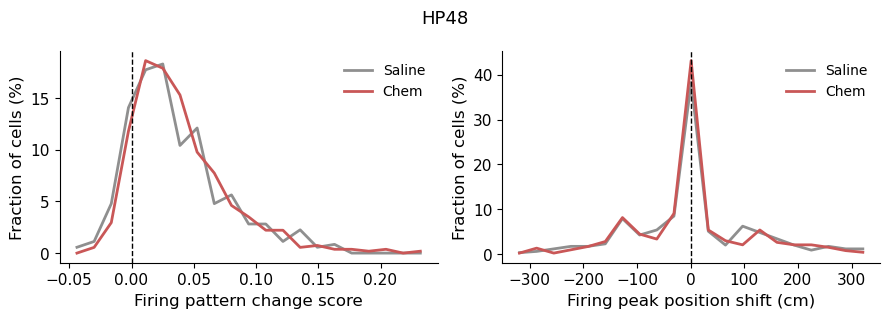

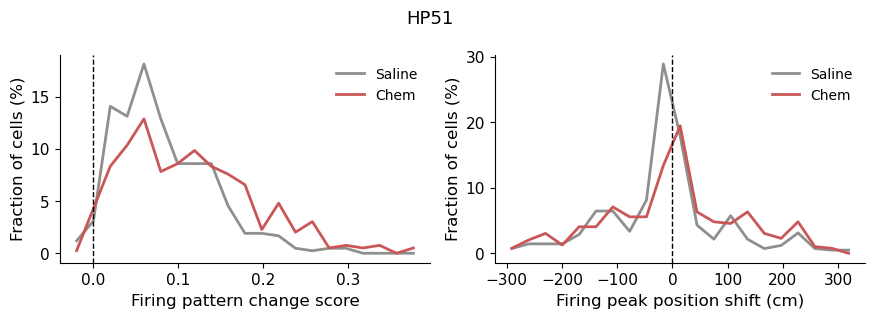

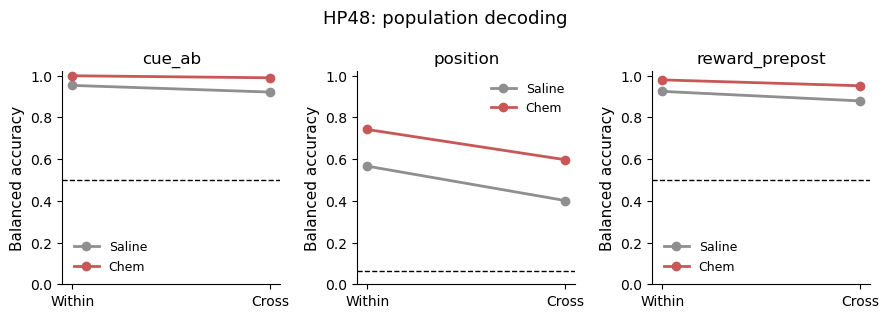

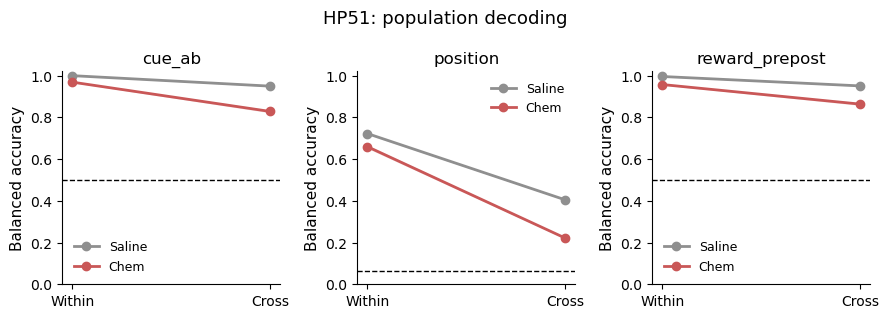

In [81]:
results = run_injection_analysis(COMPARE_ROOT)
plt.show()